# 01 · Exploratory Data Analysis

**Question:** which students fail Portuguese (final grade G3 < 10/20), and what could a teacher
see *early* that signals it?

Data: UCI *Student Performance*, Portuguese course, 649 students, two schools (GP, MS).
Cleaning rules live in `src/data.py` (see Phase 1). This notebook only reads the cleaned data.

Each chart is followed by **Observations** (what the data shows) and, where relevant,
**So what for modelling** (what it changes in Phase 3).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import PASS_MARK, load_clean

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colours: two validated categorical slots + neutral inks (see dataviz palette).
PASS_C, RISK_C = "#2a78d6", "#eb6834"      # blue = passed, orange = at risk
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white")

def rate_bars(ax, table, color=RISK_C, xlabel=""):
    """Bar chart of at-risk rate per group, labelled with rate and group size."""
    x = np.arange(len(table))
    ax.bar(x, table["rate"] * 100, color=color, width=0.6, edgecolor="white", linewidth=2)
    for i, (rate, n) in enumerate(zip(table["rate"], table["n"])):
        ax.text(i, rate * 100 + 1.5, f"{rate:.0%}", ha="center", color=INK, fontsize=9)
        ax.text(i, -7, f"n={n}", ha="center", color=INK_2, fontsize=8)
    ax.set_xticks(x, table.index.astype(str))
    ax.set_ylabel("% at risk")
    ax.set_xlabel(xlabel, labelpad=14)
    ax.set_ylim(0, max(table["rate"] * 100) + 12)

def risk_table(df, col):
    return df.groupby(col)["at_risk"].agg(n="count", rate="mean")

df = load_clean("por")
OVERALL = df["at_risk"].mean()
print(f"{len(df)} students, {df['at_risk'].sum()} at risk ({OVERALL:.1%})")

649 students, 100 at risk (15.4%)


## 1 · How many students fail, and what does the grade distribution look like?

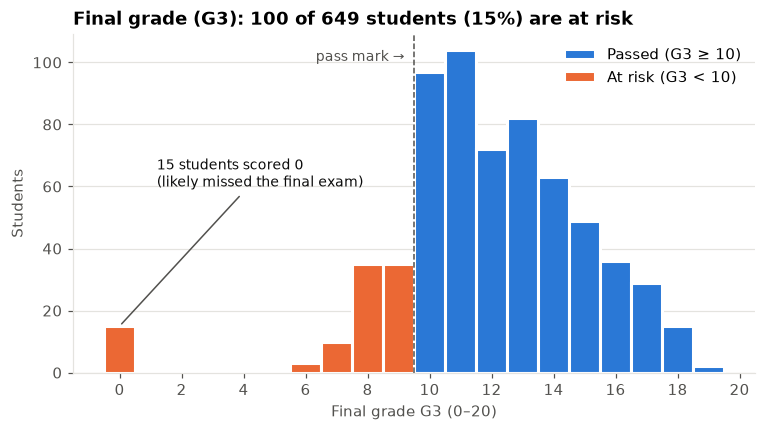

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-0.5, 20.5, 1)
ax.hist(df.loc[df.G3 >= PASS_MARK, "G3"], bins=bins, color=PASS_C, edgecolor="white", linewidth=2, label="Passed (G3 ≥ 10)")
ax.hist(df.loc[df.G3 < PASS_MARK, "G3"], bins=bins, color=RISK_C, edgecolor="white", linewidth=2, label="At risk (G3 < 10)")
ax.axvline(PASS_MARK - 0.5, color=INK_2, linestyle="--", linewidth=1)
ax.text(PASS_MARK - 0.8, ax.get_ylim()[1] * 0.92, "pass mark →", ha="right", color=INK_2, fontsize=9)
n0 = int((df.G3 == 0).sum())
ax.annotate(f"{n0} students scored 0\n(likely missed the final exam)", xy=(0, n0), xytext=(1.2, 60),
            color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK_2))
ax.set_title(f"Final grade (G3): {df.at_risk.sum()} of {len(df)} students ({OVERALL:.0%}) are at risk")
ax.set_xlabel("Final grade G3 (0–20)"); ax.set_ylabel("Students")
ax.set_xticks(range(0, 21, 2)); ax.legend(loc="upper right")
save(fig, "01_target_distribution"); plt.show()

**Observations**
- 100 of 649 students (15.4%) are at risk: an **imbalanced** problem, about 1 in 6.
- Most failing students score 7–9, just under the pass mark. They are close to passing, which is the group early support could most realistically help.
- There is a separate spike at **G3 = 0** (15 students). All 15 have 0 recorded absences, which points to missing the final exam rather than a real zero (handled in `src/data.py`: kept and flagged).

**So what for modelling:** accuracy is misleading here. A model that says "everyone passes" scores 85%.
We use **recall on the at-risk class** as the main metric, with precision, F1 and ROC-AUC alongside it.

## 2 · Past failures: the strongest single warning sign

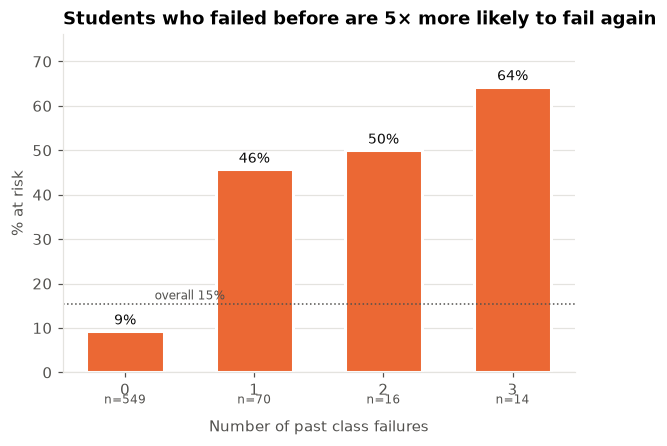

In [3]:
t = risk_table(df, "failures")
fig, ax = plt.subplots(figsize=(6, 4))
rate_bars(ax, t, xlabel="Number of past class failures")
ax.axhline(OVERALL * 100, color=INK_2, linestyle=":", linewidth=1)
ax.text(0.5, OVERALL * 100 + 1, f"overall {OVERALL:.0%}", ha="center", color=INK_2, fontsize=8)
ax.set_title("Students who failed before are 5× more likely to fail again")
save(fig, "02_failures"); plt.show()

**Observations**
- 9% of students with no past failures are at risk, versus **46–64%** of those with one or more.
- But only 100 students have any past failure, so this feature alone misses most at-risk students: the simple rule "flag if failures ≥ 1" catches about **49%** of them (recall 0.49, precision 0.49).

**So what for modelling:** that rule is the **baseline Version A has to beat**. A model is only useful if it finds the at-risk students who have *no* failure history.

## 3 · School and location: is MS's high failure rate just a rural effect?

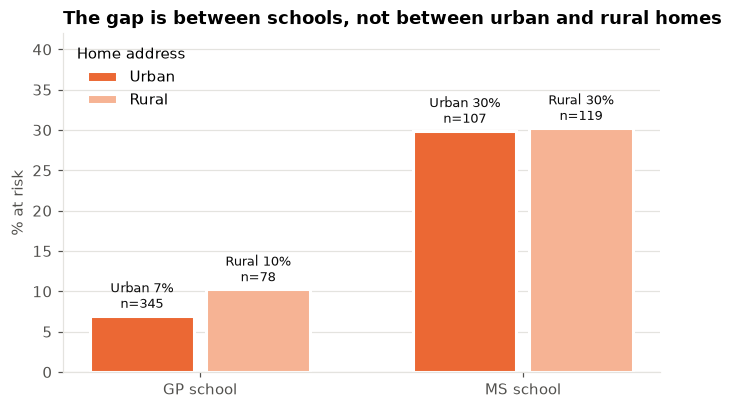

,students,at_risk,mean_past_failures,mother_edu,travel_time,internet_at_home,urban,zero_grade_students
school,,,,,,,,
GP,423,0.08,0.17,2.73,1.43,0.84,0.82,1
MS,226,0.30,0.31,2.12,1.83,0.63,0.47,14


In [4]:
t = df.groupby(["school", "address"])["at_risk"].agg(n="count", rate="mean").reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
schools, w = ["GP", "MS"], 0.36
# Both bars measure at-risk rate, so both use the at-risk orange; the tint separates urban/rural.
for j, (addr, color, label) in enumerate([("U", RISK_C, "Urban"), ("R", "#f6b394", "Rural")]):
    sub = t[t.address == addr].set_index("school").loc[schools]
    x = np.arange(len(schools)) + (j - 0.5) * w
    ax.bar(x, sub.rate * 100, width=w - 0.04, color=color, label=label, edgecolor="white", linewidth=2)
    for xi, r, n in zip(x, sub.rate, sub.n):
        ax.text(xi, r * 100 + 1, f"{label} {r:.0%}\nn={n}", ha="center", color=INK, fontsize=8.5)
ax.set_xticks(range(len(schools)), ["GP school", "MS school"])
ax.set_ylabel("% at risk"); ax.set_ylim(0, 42); ax.legend(title="Home address", loc="upper left")
ax.set_title("The gap is between schools, not between urban and rural homes")
save(fig, "03_school_address"); plt.show()

profile = df.groupby("school").agg(
    students=("at_risk", "size"), at_risk=("at_risk", "mean"),
    mean_past_failures=("failures", "mean"), mother_edu=("Medu", "mean"),
    travel_time=("traveltime", "mean"),
    internet_at_home=("internet", lambda s: (s == "yes").mean()),
    urban=("address", lambda s: (s == "U").mean()),
    zero_grade_students=("no_final_exam", "sum"),
).round(2)
profile

**Observations**
- At-risk rate is **30% at MS vs 8% at GP**.
- Within each school, urban and rural students fail at almost the same rate (MS: 30% vs 30%; GP: 7% vs 10%). So the "rural" effect seen overall mostly reflects **which school** rural students attend (MS is 53% rural, GP 18%).
- MS students on average have more past failures, mothers with less formal education, longer travel and less home internet. 14 of the 15 G3 = 0 students are at MS.
- This data cannot tell us **why** MS differs: the student intake, the teaching, grading standards or dropout patterns could all contribute.

**So what for modelling:** `school` will be a strong predictor, and that's a **fairness question** for Phase 4.
A model that mainly learns "MS → at risk" would be accurate on this data but useless (and unfair) for a teacher inside one school.
We'll check recall separately for each school.

## 4 · Study habits and ambition

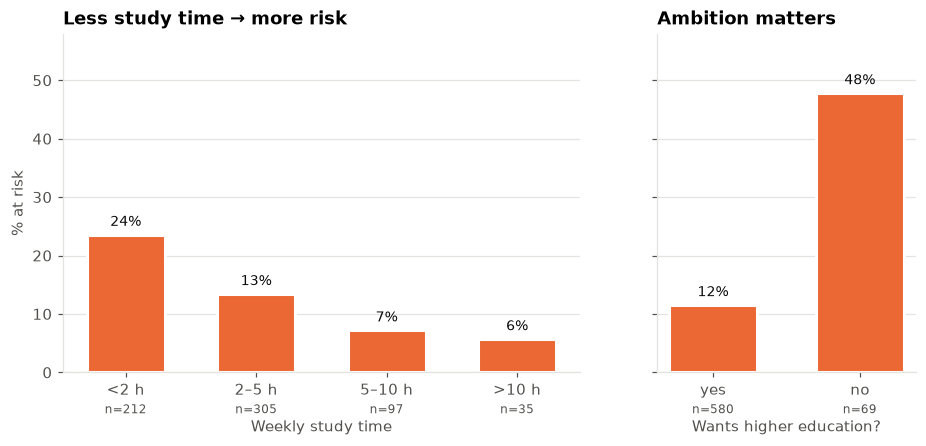

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, gridspec_kw={"width_ratios": [4, 2]})
st = risk_table(df, "studytime")
st.index = ["<2 h", "2–5 h", "5–10 h", ">10 h"]
rate_bars(axes[0], st, xlabel="Weekly study time")
axes[0].set_title("Less study time → more risk")
hi = risk_table(df, "higher").loc[["yes", "no"]]
rate_bars(axes[1], hi, xlabel="Wants higher education?")
axes[1].set_title("Ambition matters"); axes[1].set_ylabel("")
for ax in axes: ax.set_ylim(0, 58)
save(fig, "04_study_and_ambition"); plt.show()

**Observations**
- At-risk rate falls steadily with study time: **24%** for under 2 h/week down to **6%** for over 10 h.
- Students who **don't plan on higher education** are at risk 48% of the time, versus 12% for those who do. Only 69 students say "no", so it's a small but very concentrated group.
- Both are things a teacher can learn in a day-1 questionnaire, which makes them good Version A features.

**So what for modelling:** these are self-reported survey answers. They're useful, but students can give socially desirable answers, and the questionnaire has to be one a school would actually run.

## 5 · Absences, and a data-quality trap

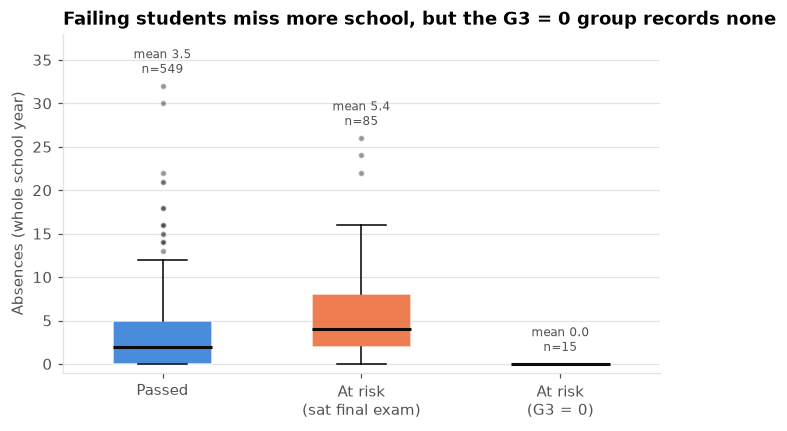

In [6]:
groups = {
    "Passed": df[(df.at_risk == 0)].absences,
    "At risk\n(sat final exam)": df[(df.at_risk == 1) & (df.no_final_exam == 0)].absences,
    "At risk\n(G3 = 0)": df[df.no_final_exam == 1].absences,
}
fig, ax = plt.subplots(figsize=(7, 4))
colors = [PASS_C, RISK_C, INK_2]
bp = ax.boxplot(list(groups.values()), tick_labels=list(groups.keys()), patch_artist=True,
                widths=0.5, showfliers=True, medianprops=dict(color=INK, linewidth=2),
                flierprops=dict(marker="o", markersize=4, markerfacecolor=INK_2, markeredgecolor="white", alpha=0.6))
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor("white")
for i, s in enumerate(groups.values(), start=1):
    ax.text(i, s.max() + 1.5, f"mean {s.mean():.1f}\nn={len(s)}", ha="center", color=INK_2, fontsize=8)
ax.set_ylabel("Absences (whole school year)"); ax.set_ylim(-1, 38)
ax.set_title("Failing students miss more school, but the G3 = 0 group records none")
save(fig, "05_absences"); plt.show()

**Observations**
- Students who failed but sat the exam average **5.4 absences**, versus **3.5** for those who passed.
- The 15 G3 = 0 students all show **0** absences. If they really left school, their attendance stopped being recorded, so "0 absences" here probably means *missing data*, not perfect attendance. Mixing them in hides the absence signal (the at-risk mean drops to 4.6).

**So what for modelling, a leakage issue:** `absences` counts the **whole school year**.
A teacher on day 1 doesn't have this number, so strictly speaking it doesn't belong in the start-of-year model (Version A).
Options for Phase 3: (a) drop it from Version A, or (b) keep it and describe it honestly as a *prior-year attendance proxy*.
We'll train both and report the difference.

## 6 · Why G2 and G3 can never be inputs, and how strong G1 is

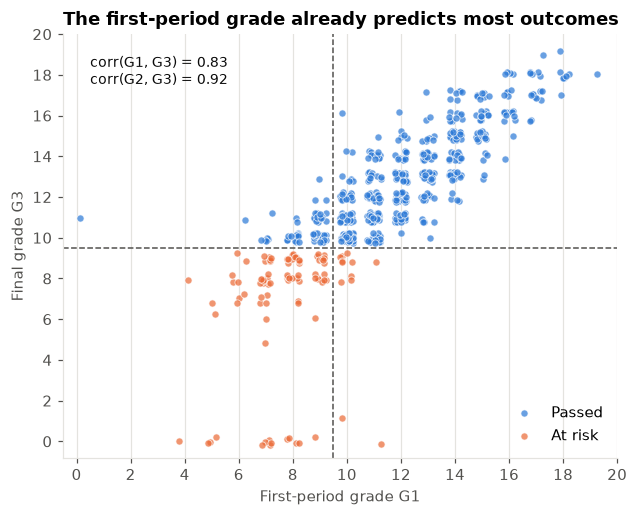

Rule 'flag if G1 < 10': recall 88%, precision 56%


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
rng = np.random.default_rng(42)
jit = lambda s: s + rng.uniform(-0.25, 0.25, len(s))   # jitter: grades are integers and overlap
for flag, c, lab in [(0, PASS_C, "Passed"), (1, RISK_C, "At risk")]:
    d = df[df.at_risk == flag]
    ax.scatter(jit(d.G1), jit(d.G3), s=22, color=c, alpha=0.7, edgecolor="white", linewidth=0.6, label=lab)
ax.axvline(PASS_MARK - 0.5, color=INK_2, linestyle="--", linewidth=1)
ax.axhline(PASS_MARK - 0.5, color=INK_2, linestyle="--", linewidth=1)
r1, r2 = df[["G1", "G3"]].corr().iloc[0, 1], df[["G2", "G3"]].corr().iloc[0, 1]
ax.text(0.5, 19, f"corr(G1, G3) = {r1:.2f}\ncorr(G2, G3) = {r2:.2f}", color=INK, fontsize=9, va="top")
ax.set_xlabel("First-period grade G1"); ax.set_ylabel("Final grade G3")
ax.set_xlim(-0.5, 20); ax.set_ylim(-0.8, 20); ax.grid(axis="both")
ax.set_xticks(range(0, 21, 2)); ax.set_yticks(range(0, 21, 2))
ax.legend(loc="lower right")
ax.set_title("The first-period grade already predicts most outcomes")
save(fig, "06_g1_vs_g3"); plt.show()

g1_rule = df.G1 < PASS_MARK
tp = (g1_rule & (df.at_risk == 1)).sum()
print(f"Rule 'flag if G1 < 10': recall {tp / df.at_risk.sum():.0%}, precision {tp / g1_rule.sum():.0%}")

**Observations**
- G3 correlates **0.83** with G1 and **0.92** with G2. G2 is recorded in the second period, months after a teacher would want to act, so a model using it would look excellent but arrive too late to help. G2 and G3 are **never** model inputs.
- The simple rule **"flag if G1 < 10"** already catches **88%** of at-risk students (precision 56%).

**So what for modelling:** for **Version B** (after the first test), the bar is **not** a dummy classifier. It's this one-line G1 rule.
If the ML model can't beat it, a teacher should just use the rule. Saying that honestly is a stronger result than an inflated accuracy number.

## Summary: what EDA changes for modelling

| Finding | Consequence for Phase 3 |
|---|---|
| 15% at risk (imbalanced) | Optimise **recall**; use `class_weight="balanced"` + threshold tuning; stratified CV |
| Past failures: 9% vs 46–64% at risk | Version A baseline = rule "failures ≥ 1" (recall 49%) |
| MS 30% vs GP 8%, not explained by urban/rural | `school` is a strong predictor → per-school recall in the fairness audit |
| Study time and higher-education plans matter | Good day-1 questionnaire features |
| `absences` counts the whole year; G3 = 0 students show 0 | Train Version A with and without `absences`; report both |
| G1 alone catches 88% of failures | Version B baseline = rule "G1 < 10", not just a dummy |
| G2/G3 correlate 0.92/1.00 with the target | Excluded via `LEAKAGE_COLS` |

Sensitive features (`sex`, `Dalc`, `Walc`, `romantic`) are left for the ethics test in Phase 4.